# Import libraries

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
from pathlib import Path
import seaborn as sns

# Finding dataset

In [24]:
PROJECT_DIR = Path.cwd()

print("Project directory:", PROJECT_DIR)

if PROJECT_DIR.name == "notebook":
    PROJECT_DIR = PROJECT_DIR.parent

Project directory: /Volumes/Coding Work Place/Deep learning Envirnoment Audio Detection/notebooks


In [25]:
DATASET_DIR = PROJECT_DIR / "ESC-50"
AUDIO_DIR = DATASET_DIR / "audio"

In [26]:
print("Project directory:", PROJECT_DIR)
print("Dataset:", DATASET_DIR)
print("Audio folder:", AUDIO_DIR)

# print("Dataset found:", DATASET_DIR.exists())
# print("Audio folder found:", AUDIO_DIR.exists())
# print("Metadata found:", METADATA_FILE.exists())

Project directory: /Volumes/Coding Work Place/Deep learning Envirnoment Audio Detection/notebooks
Dataset: /Volumes/Coding Work Place/Deep learning Envirnoment Audio Detection/notebooks/ESC-50
Audio folder: /Volumes/Coding Work Place/Deep learning Envirnoment Audio Detection/notebooks/ESC-50/audio


# Load the metadata

In [27]:
df = pd.read_csv("../ESC-50/meta/esc50.csv")

df

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A
...,...,...,...,...,...,...,...
1995,5-263831-B-6.wav,5,6,hen,False,263831,B
1996,5-263902-A-36.wav,5,36,vacuum_cleaner,False,263902,A
1997,5-51149-A-25.wav,5,25,footsteps,False,51149,A
1998,5-61635-A-8.wav,5,8,sheep,False,61635,A


In [28]:
display(df.shape)
display(df.info())

(2000, 7)

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   filename  2000 non-null   str  
 1   fold      2000 non-null   int64
 2   target    2000 non-null   int64
 3   category  2000 non-null   str  
 4   esc10     2000 non-null   bool 
 5   src_file  2000 non-null   int64
 6   take      2000 non-null   str  
dtypes: bool(1), int64(3), str(3)
memory usage: 95.8 KB


None

Expected result
2,000 recordings
50 sound classes
40 recordings per class

# Check class distribution

In [29]:
classes_count = df.category.value_counts()
classes_count

category
dog                 40
chirping_birds      40
vacuum_cleaner      40
thunderstorm        40
door_wood_knock     40
can_opening         40
crow                40
clapping            40
fireworks           40
chainsaw            40
airplane            40
mouse_click         40
pouring_water       40
train               40
sheep               40
water_drops         40
church_bells        40
clock_alarm         40
keyboard_typing     40
wind                40
footsteps           40
frog                40
cow                 40
brushing_teeth      40
car_horn            40
crackling_fire      40
helicopter          40
drinking_sipping    40
rain                40
insects             40
laughing            40
hen                 40
engine              40
breathing           40
crying_baby         40
hand_saw            40
coughing            40
glass_breaking      40
snoring             40
toilet_flush        40
pig                 40
washing_machine     40
clock_tick          40
sn

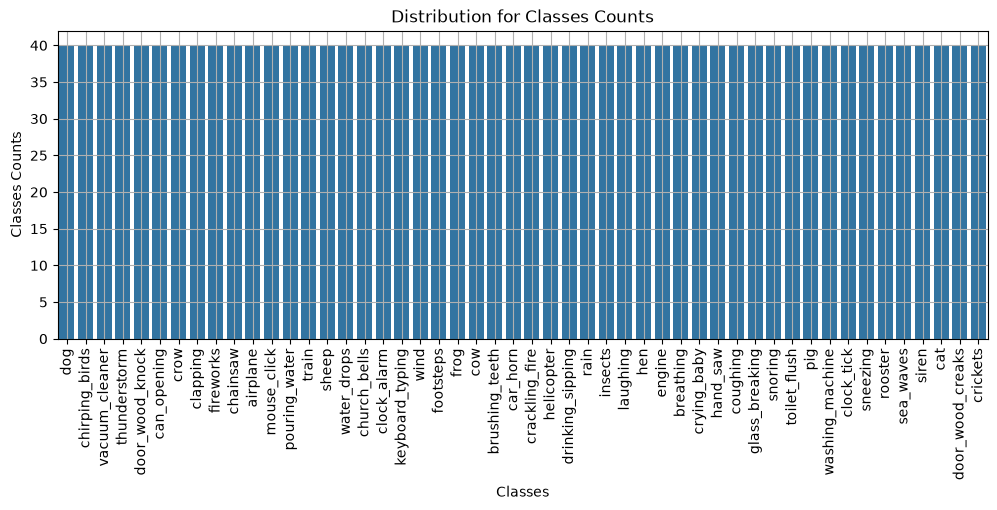

In [39]:
plt.figure(figsize=(12, 4))

plt.title("Distribution for Classes Counts")

sns.barplot(classes_count)

plt.xlabel("Classes")
plt.ylabel("Classes Counts")
plt.grid()

plt.xticks(rotation=90)

plt.show()